# Dia 27 — Validação de Dados com Pandera em Pipelines de Data Science

**Fase 1 — Python Basics (reta final)** · 26/11/2026 · Gutemberg Rapôso

### O que é validação de dados?

Validar dados é verificar, **de forma explícita e automatizada**, se um conjunto de dados obedece a um *contrato*: tipos de colunas, faixas de valores, categorias permitidas, ausência de duplicatas, relações entre colunas e até propriedades estatísticas.

### Por que isso importa em pipelines de DS?

- **Falhas silenciosas:** um modelo treinado com `age = -5` ou `score = 999` não quebra — ele apenas aprende errado.
- **Contratos entre etapas:** cada função de um pipeline assume algo sobre sua entrada; a validação torna essas suposições *verificáveis*.
- **Depuração mais rápida:** relatórios de falhas mostram *onde* e *por que* os dados violaram o contrato.
- **Produção:** dados mudam com o tempo (*data drift*); esquemas detectam isso antes que métricas degradem.

Em linguística de corpus e avaliação educacional isso é muito familiar: um nível CEFR inexistente (`"B3"`) ou uma nota fora da escala invalida qualquer análise posterior.

### Roteiro
1. Conceitos básicos: `DataFrameSchema`, `Column`, `Check` (dataset *tips*)
2. Inferência de esquemas (*titanic*)
3. Decorators `@check_input` / `@check_output` (*penguins*)
4. Checks customizados e testes de hipótese (*titanic*)
5. `DataFrameModel` (esquemas baseados em classes) — dados de avaliação de aprendizes de inglês
6. Integração com pipelines do scikit-learn (*iris*)
7. Relatórios de validação e visualização

> Datasets usados: built-ins do seaborn (`tips`, `titanic`, `penguins`) e scikit-learn (`iris`). A seção 5 usa dados **sintéticos, explicitamente rotulados**, gerados com semente fixa apenas para demonstrar a API.

## 0. Instalação e imports

Se necessário: `pip install pandera scipy`. Desde a versão 0.24, o import recomendado para DataFrames pandas é `import pandera.pandas as pa`.

In [1]:
# !pip install pandera scipy  # uncomment if pandera is not installed
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandera
import pandera.pandas as pa
import seaborn as sns
import sklearn
from pandera.errors import SchemaError, SchemaErrors
from pandera.typing import DataFrame, Series

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

print(f"pandas  {pd.__version__}")
print(f"pandera {pandera.__version__}")
print(f"seaborn {sns.__version__}")
print(f"sklearn {sklearn.__version__}")

pandas  2.3.3
pandera 0.36.0
seaborn 0.13.2
sklearn 1.9.1


## 1. Conceitos básicos: `DataFrameSchema`, `Column` e `Check`

- **`DataFrameSchema`**: o contrato do DataFrame inteiro (colunas, índice, opções como `strict` e `coerce`).
- **`Column`**: tipo esperado, se aceita nulos, se deve ser único, e uma lista de checks.
- **`Check`**: uma regra booleana — há checks prontos (`ge`, `le`, `isin`, `in_range`, `str_matches`...) e checks customizados com funções.

Vamos começar com o dataset `tips` (gorjetas de um restaurante).

In [2]:
tips = sns.load_dataset("tips")
print(tips.shape)
print(tips.dtypes)
tips.head()

(244, 7)
total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
# Categorical columns in seaborn's tips are pandas 'category'; we validate their allowed values.
tips_schema = pa.DataFrameSchema(
    columns={
        "total_bill": pa.Column(float, checks=[pa.Check.gt(0), pa.Check.le(100)]),
        "tip": pa.Column(float, checks=pa.Check.in_range(0, 20)),
        "sex": pa.Column("category", checks=pa.Check.isin(["Male", "Female"])),
        "smoker": pa.Column("category", checks=pa.Check.isin(["Yes", "No"])),
        "day": pa.Column("category", checks=pa.Check.isin(["Thur", "Fri", "Sat", "Sun"])),
        "time": pa.Column("category", checks=pa.Check.isin(["Lunch", "Dinner"])),
        "size": pa.Column(int, checks=pa.Check.in_range(1, 10)),
    },
    # DataFrame-level (wide) check: a tip should never exceed the bill itself.
    checks=pa.Check(lambda df: df["tip"] <= df["total_bill"], error="tip <= total_bill"),
    strict=True,  # no unexpected columns allowed
    name="TipsSchema",
)

validated = tips_schema.validate(tips)
print(f"✅ tips passed validation: {validated.shape[0]} rows")

✅ tips passed validation: 244 rows


### Tratando erros de validação

Por padrão, a validação é **eager**: para no primeiro erro e lança `SchemaError`. Vamos corromper uma cópia dos dados para ver o comportamento e capturar a exceção de forma elegante.

In [4]:
tips_bad = tips.copy()
tips_bad.loc[0, "total_bill"] = -10.0  # impossible bill
tips_bad.loc[1, "size"] = 0            # party with zero people

try:
    tips_schema.validate(tips_bad)
except SchemaError as err:
    print("❌ SchemaError (eager mode) — first failure only")
    print("column :", err.schema.name if hasattr(err.schema, "name") else None)
    print("check  :", err.check)
    print("failure cases:")
    print(err.failure_cases)

❌ SchemaError (eager mode) — first failure only
column : total_bill
check  : <Check greater_than: greater_than(0)>
failure cases:
   index  failure_case
0      0         -10.0


In [5]:
def safe_validate(df: pd.DataFrame, schema: pa.DataFrameSchema) -> tuple[bool, pd.DataFrame | None]:
    """Validate lazily and return (is_valid, failure_cases) instead of raising.

    Lazy mode collects *all* failures, which is what you want for reports.
    """
    try:
        schema.validate(df, lazy=True)
        return True, None
    except SchemaErrors as err:
        return False, err.failure_cases


tips_bad["day"] = tips_bad["day"].astype(str)
tips_bad.loc[2, "day"] = "Mon"  # a day the restaurant data never contains
tips_bad["day"] = tips_bad["day"].astype("category")

ok, failures = safe_validate(tips_bad, tips_schema)
print("valid?", ok)
failures[["schema_context", "column", "check", "failure_case", "index"]]

valid? False


,schema_context,column,check,failure_case,index
3,DataFrameSchema,total_bill,tip <= total_bill,-10.0,0
4,DataFrameSchema,tip,tip <= total_bill,1.01,0
5,DataFrameSchema,sex,tip <= total_bill,Female,0
6,DataFrameSchema,smoker,tip <= total_bill,No,0
7,DataFrameSchema,day,tip <= total_bill,Sun,0
8,DataFrameSchema,time,tip <= total_bill,Dinner,0
9,DataFrameSchema,size,tip <= total_bill,2,0
0,Column,total_bill,greater_than(0),-10.0,0
1,Column,day,"isin(['Thur', 'Fri', 'Sat', 'Sun'])",Mon,2
2,Column,size,"in_range(1, 10)",0,1


**Nota:** checks no nível do DataFrame (como `tip <= total_bill`) reportam a linha inteira — por isso a linha 0 aparece uma vez para cada coluna. O modo `lazy=True` é essencial para relatórios — em vez de corrigir um erro por vez, vemos todos de uma vez. A coluna `failure_case` mostra o valor problemático e `index` aponta a linha.

### Coerção de tipos

Com `coerce=True`, o Pandera tenta converter os tipos antes de validar — útil quando dados chegam de CSVs como strings.

In [6]:
coerce_schema = pa.DataFrameSchema(
    {"total_bill": pa.Column(float, pa.Check.gt(0), coerce=True),
     "size": pa.Column(int, pa.Check.ge(1), coerce=True)}
)
raw = pd.DataFrame({"total_bill": ["16.99", "10.34"], "size": ["2", "3"]})
print(raw.dtypes.to_dict())
coerced = coerce_schema.validate(raw)
print(coerced.dtypes.to_dict())
coerced

{'total_bill': dtype('O'), 'size': dtype('O')}
{'total_bill': dtype('float64'), 'size': dtype('int64')}


,total_bill,size
0,16.99,2
1,10.34,3


## 2. Inferência de esquemas a partir de DataFrames existentes

Escrever esquemas à mão para datasets largos é trabalhoso. `pa.infer_schema()` gera um **rascunho** a partir dos dados: tipos, nulidade e faixas observadas (min/max). É um ponto de partida — **nunca** a verdade final, pois ele apenas descreve a amostra vista.

In [7]:
titanic = sns.load_dataset("titanic")
print(titanic.shape)
print(titanic.isna().sum()[lambda s: s > 0])
titanic.head(3)

(891, 15)
age            177
embarked         2
deck           688
embark_town      2
dtype: int64


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True


In [8]:
inferred = pa.infer_schema(titanic)
print(type(inferred).__name__, "with", len(inferred.columns), "columns")
for name, col in list(inferred.columns.items())[:8]:
    print(f"{name:<10} dtype={str(col.dtype):<10} nullable={col.nullable!s:<5} checks={[str(c) for c in col.checks]}")

DataFrameSchema with 15 columns
survived   dtype=int64      nullable=False checks=['<Check greater_than_or_equal_to: greater_than_or_equal_to(0.0)>', '<Check less_than_or_equal_to: less_than_or_equal_to(1.0)>']
pclass     dtype=int64      nullable=False checks=['<Check greater_than_or_equal_to: greater_than_or_equal_to(1.0)>', '<Check less_than_or_equal_to: less_than_or_equal_to(3.0)>']
sex        dtype=object     nullable=False checks=[]
age        dtype=float64    nullable=True  checks=['<Check greater_than_or_equal_to: greater_than_or_equal_to(0.42)>', '<Check less_than_or_equal_to: less_than_or_equal_to(80.0)>']
sibsp      dtype=int64      nullable=False checks=['<Check greater_than_or_equal_to: greater_than_or_equal_to(0.0)>', '<Check less_than_or_equal_to: less_than_or_equal_to(8.0)>']
parch      dtype=int64      nullable=False checks=['<Check greater_than_or_equal_to: greater_than_or_equal_to(0.0)>', '<Check less_than_or_equal_to: less_than_or_equal_to(6.0)>']
fare       dtype=f

In [9]:
# The inferred schema can be exported as Python code and versioned alongside the pipeline.
# to_script() needs 'black' for formatting; fall back to YAML (needs PyYAML) if it is missing.
try:
    script = inferred.to_script()
except ImportError:
    script = inferred.to_yaml()
print("\n".join(script.splitlines()[:25]))
print("...")

schema_type: dataframe
api: pandas
columns:
  survived:
    dtype: int64
    greater_than_or_equal_to: 0.0
    less_than_or_equal_to: 1.0
  pclass:
    dtype: int64
    greater_than_or_equal_to: 1.0
    less_than_or_equal_to: 3.0
  sex:
    dtype: object
  age:
    dtype: float64
    nullable: true
    greater_than_or_equal_to: 0.42
    less_than_or_equal_to: 80.0
  sibsp:
    dtype: int64
    greater_than_or_equal_to: 0.0
    less_than_or_equal_to: 8.0
  parch:
    dtype: int64
    greater_than_or_equal_to: 0.0
...


### Customizando o esquema inferido

O esquema inferido usa as faixas exatas observadas (ex.: `fare <= 512.33`). Isso é **restritivo demais**: um novo passageiro com tarifa de 600 seria rejeitado. Vamos substituir por regras de domínio:
- `age > 0` e `age <= 100` (nulos permitidos — idade é desconhecida para ~20% dos passageiros);
- `fare >= 0` (há tarifas zero, possivelmente tripulação/convidados);
- `pclass` ∈ {1, 2, 3} e coerência entre `survived` e `alive`.

In [10]:
titanic_schema = (
    inferred
    .update_column("age", checks=[pa.Check.gt(0), pa.Check.le(100)], nullable=True)
    .update_column("fare", checks=[pa.Check.ge(0)])
    .update_column("pclass", checks=[pa.Check.isin([1, 2, 3])])
    .update_column("survived", checks=[pa.Check.isin([0, 1])])
    .update_column("sibsp", checks=[pa.Check.ge(0)])
    .update_column("parch", checks=[pa.Check.ge(0)])
)

# Cross-column consistency: 'alive' must be the text version of 'survived'.
titanic_schema = pa.DataFrameSchema(
    columns=titanic_schema.columns,
    name="TitanicCustomized",
    checks=[
    pa.Check(
        lambda df: (df["survived"] == 1) == (df["alive"] == "yes"),
        error="survived/alive consistency",
    ),
    pa.Check(
        lambda df: df["pclass"].map({1: "First", 2: "Second", 3: "Third"}) == df["class"].astype(str),
        error="pclass/class consistency",
    ),
    ],
)

titanic_valid = titanic_schema.validate(titanic, lazy=True)
print("✅ titanic passed the customized schema:", titanic_valid.shape)

✅ titanic passed the customized schema: (891, 15)


In [11]:
# A new (hypothetical) passenger with a fare above the observed max now passes,
# while an impossible age is rejected.
new_rows = titanic.head(2).copy()
new_rows.loc[new_rows.index[0], "fare"] = 600.0   # plausible: above observed max
new_rows.loc[new_rows.index[1], "age"] = -3.0     # impossible

for label, sch in [("inferred", inferred), ("customized", titanic_schema)]:
    ok, fc = safe_validate(new_rows, sch)
    print(f"{label:<11} valid={ok}")
    if fc is not None:
        print(fc[["column", "check", "failure_case"]].to_string(index=False))

inferred    valid=False
column                           check  failure_case
   age  greater_than_or_equal_to(0.42)          -3.0
  fare less_than_or_equal_to(512.3292)         600.0
customized  valid=False
column           check  failure_case
   age greater_than(0)          -3.0


**Lição:** o esquema inferido rejeitou uma tarifa plausível (falso positivo) porque copiou o máximo da amostra. O esquema customizado codifica **conhecimento de domínio**, não estatísticas da amostra.

## 3. Decorators: `@pa.check_input` e `@pa.check_output`

Decorators permitem validar automaticamente a entrada e a saída de funções — cada etapa do pipeline passa a ter um contrato explícito. Vamos construir um pipeline de limpeza para o dataset `penguins`.

In [12]:
penguins = sns.load_dataset("penguins")
print(penguins.shape)
print(penguins.isna().sum())
penguins.head()

(344, 7)
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [13]:
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
ISLANDS = ["Biscoe", "Dream", "Torgersen"]

# Raw contract: types and plausible ranges, but nulls are allowed.
raw_penguins_schema = pa.DataFrameSchema(
    {
        "species": pa.Column(str, pa.Check.isin(SPECIES)),
        "island": pa.Column(str, pa.Check.isin(ISLANDS)),
        "bill_length_mm": pa.Column(float, pa.Check.in_range(25, 70), nullable=True),
        "bill_depth_mm": pa.Column(float, pa.Check.in_range(10, 25), nullable=True),
        "flipper_length_mm": pa.Column(float, pa.Check.in_range(150, 250), nullable=True),
        "body_mass_g": pa.Column(float, pa.Check.in_range(2000, 7000), nullable=True),
        "sex": pa.Column(str, pa.Check.isin(["Male", "Female"]), nullable=True),
    },
    name="RawPenguins",
)

# Clean contract: same ranges, no nulls, plus an engineered feature.
clean_penguins_schema = raw_penguins_schema.update_columns(
    {c: {"nullable": False} for c in raw_penguins_schema.columns}
)
clean_penguins_schema.name = "CleanPenguins"

featured_penguins_schema = clean_penguins_schema.add_columns(
    {"bill_ratio": pa.Column(float, pa.Check.in_range(1.0, 4.5))}
)
featured_penguins_schema.name = "FeaturedPenguins"
print(featured_penguins_schema.columns.keys())

dict_keys(['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'bill_ratio'])


In [14]:
@pa.check_input(raw_penguins_schema)
@pa.check_output(clean_penguins_schema)
def drop_incomplete(df: pd.DataFrame) -> pd.DataFrame:
    """Remove rows with any missing value (11 penguins lack 'sex')."""
    return df.dropna().reset_index(drop=True)


@pa.check_input(clean_penguins_schema)
@pa.check_output(featured_penguins_schema)
def add_bill_ratio(df: pd.DataFrame) -> pd.DataFrame:
    """Add bill_length / bill_depth, a shape feature that separates Gentoo well."""
    return df.assign(bill_ratio=df["bill_length_mm"] / df["bill_depth_mm"])


@pa.check_io(df=featured_penguins_schema, out=featured_penguins_schema)
def standardize_mass(df: pd.DataFrame) -> pd.DataFrame:
    """Convert body mass to kilograms? No — keep grams; just round to the nearest 25 g."""
    return df.assign(body_mass_g=(df["body_mass_g"] / 25).round() * 25)


pipeline_out = penguins.pipe(drop_incomplete).pipe(add_bill_ratio).pipe(standardize_mass)
print(f"✅ pipeline finished: {penguins.shape} -> {pipeline_out.shape}")
pipeline_out.groupby("species")["bill_ratio"].describe().round(2)

✅ pipeline finished: (344, 7) -> (333, 8)


,count,mean,std,min,25%,50%,75%,max
species,,,,,,,,
Adelie,146.0,2.12,0.16,1.64,2.01,2.14,2.24,2.45
Chinstrap,68.0,2.65,0.15,2.35,2.56,2.66,2.73,3.26
Gentoo,119.0,3.18,0.17,2.57,3.07,3.17,3.29,3.61


### O que acontece quando uma etapa quebra o contrato?

Abaixo, uma função "bugada" esquece de remover nulos. O decorator `@check_output` detecta o problema **na fronteira da função**, com uma mensagem que indica a função culpada.

In [15]:
@pa.check_output(clean_penguins_schema)
def buggy_cleaning(df: pd.DataFrame) -> pd.DataFrame:
    """Bug: only drops rows with missing bill length, forgetting 'sex'."""
    return df.dropna(subset=["bill_length_mm"])


try:
    buggy_cleaning(penguins)
except SchemaError as err:
    msg = str(err).splitlines()[0]
    print("❌ caught at the function boundary:\n", msg[:300])

❌ caught at the function boundary:
 error in check_output decorator of function 'buggy_cleaning': non-nullable series 'sex' contains null values:


## 4. Checks customizados e testes de hipótese

Além dos checks prontos, podemos escrever:
- **Checks elemento a elemento** (`element_wise=True`): a função recebe um valor escalar.
- **Checks vetorizados** (padrão): a função recebe uma `Series` e devolve `Series[bool]` ou `bool` — muito mais rápido.
- **Checks agrupados** (`groupby=`): a função recebe um dicionário `{grupo: Series}`.
- **`pa.Hypothesis`**: checks estatísticos (ex.: teste t entre grupos), usando `scipy`.

In [16]:
# 1) Vectorized custom check — the 'title' embedded in 'who' should agree with 'sex'.
who_sex_check = pa.Check(
    lambda df: ~((df["who"] == "man") & (df["sex"] != "male")) & ~((df["who"] == "woman") & (df["sex"] != "female")),
    error="who/sex agreement",
)

# 2) Element-wise check — embark_town must be a non-empty capitalized word (or null).
capitalized = pa.Check(lambda x: isinstance(x, str) and x[:1].isupper(), element_wise=True, error="capitalized")

# 3) Aggregate check — at most 25% of ages may be missing (data completeness contract).
def max_missing_ratio(limit: float):
    """Build a Series-level check that bounds the share of missing values."""
    return pa.Check(lambda s: s.isna().mean() <= limit, error=f"missing ratio <= {limit:.0%}", ignore_na=False)

# 4) Grouped check — children ('who' == 'child') must be younger than 16 on average... per class.
child_age_check = pa.Check(
    lambda groups: all(s.mean() < 16 for s in groups.values()),
    groupby="pclass", error="mean child age < 16 in every class",
)

custom_schema = pa.DataFrameSchema(
    {
        "age": pa.Column(float, [pa.Check.gt(0), max_missing_ratio(0.25)], nullable=True),
        "embark_town": pa.Column(str, capitalized, nullable=True),
    },
    checks=[who_sex_check],
)
custom_schema.validate(titanic, lazy=True)

children = titanic.loc[titanic["who"] == "child", ["age", "pclass"]]
pa.DataFrameSchema({"age": pa.Column(float, child_age_check), "pclass": pa.Column(int)}).validate(children)
print("✅ custom checks passed")
print(f"missing age ratio: {titanic['age'].isna().mean():.1%}")

✅ custom checks passed
missing age ratio: 19.9%


### Testes de hipótese com `pa.Hypothesis`

Podemos transformar uma **expectativa estatística** em contrato. Hipótese: a tarifa média da 1ª classe é maior que a da 3ª classe. Usamos `two_sample_ttest` com `relationship="greater_than"`.

> Atenção: tarifas são muito assimétricas; o teste t de Welch é razoavelmente robusto com amostras grandes (216 vs 491), mas aqui o objetivo é **monitorar** uma propriedade conhecida dos dados — não fazer inferência causal.

In [17]:
fare_hypothesis_schema = pa.DataFrameSchema(
    {
        "fare": pa.Column(
            float,
            checks=pa.Hypothesis.two_sample_ttest(
                sample1=1, sample2=3, groupby="pclass",
                relationship="greater_than", alpha=0.01, equal_var=False,
            ),
        ),
        "pclass": pa.Column(int),
    }
)
fare_hypothesis_schema.validate(titanic[["fare", "pclass"]])

means = titanic.groupby("pclass")["fare"].agg(["mean", "median", "count"]).round(2)
print("✅ Hypothesis check passed: mean fare (1st class) > mean fare (3rd class), alpha=0.01")
means

✅ Hypothesis check passed: mean fare (1st class) > mean fare (3rd class), alpha=0.01


,mean,median,count
pclass,,,
1,84.15,60.29,216
2,20.66,14.25,184
3,13.68,8.05,491


In [18]:
# The same hypothesis in the opposite direction must FAIL — sanity check that the test is informative.
wrong_direction = pa.DataFrameSchema(
    {
        "fare": pa.Column(float, pa.Hypothesis.two_sample_ttest(
            sample1=3, sample2=1, groupby="pclass", relationship="greater_than", alpha=0.01, equal_var=False)),
        "pclass": pa.Column(int),
    }
)
try:
    wrong_direction.validate(titanic[["fare", "pclass"]])
except SchemaError as err:
    print("❌ as expected, '3rd > 1st' is rejected:", str(err).splitlines()[0][:200])

❌ as expected, '3rd > 1st' is rejected: Column 'fare' failed series or dataframe validator 0: <Check two_sample_ttest: failed two sample ttest between '3' and '1'>


In [19]:
# A custom Hypothesis: survival rate differs by sex (chi-square test of independence).
from scipy import stats


def chi2_independent(samples: dict, alpha: float = 0.01) -> bool:
    """Return True when we reject independence between group and a binary outcome."""
    table = np.array([[s.sum(), (1 - s).sum()] for s in samples.values()])
    _, p_value, _, _ = stats.chi2_contingency(table)
    return p_value < alpha


survival_by_sex = pa.DataFrameSchema(
    {
        "survived": pa.Column(int, pa.Check(chi2_independent, groupby="sex", error="survival depends on sex")),
        "sex": pa.Column(str),
    }
)
survival_by_sex.validate(titanic[["survived", "sex"]])
print("✅ survival rate depends on sex (chi-square, alpha=0.01)")
titanic.groupby("sex")["survived"].mean().round(3)

✅ survival rate depends on sex (chi-square, alpha=0.01)


sex
female    0.742
male      0.189
Name: survived, dtype: float64

## 5. `DataFrameModel`: esquemas baseados em classes

A API de classes lembra `dataclasses`/`pydantic` (Dia 21): cada atributo tipado é uma coluna, `pa.Field` define restrições, e decorators `@pa.check` / `@pa.dataframe_check` adicionam regras customizadas. Vantagens: autocompletar, reuso por herança, e *type hints* `DataFrame[Model]` em funções.

### Dados sintéticos de avaliação de aprendizes de inglês

> ⚠️ **Dados sintéticos e rotulados como tal.** Não são dados reais de alunos. São gerados com `numpy.random.default_rng(27)` (semente fixa → reprodutível) e regras **logicamente coerentes**: a nota média cresce com o nível CEFR e com as horas de estudo. Servem apenas para demonstrar a API — nenhuma conclusão educacional deve ser tirada deles.

In [20]:
CEFR_LEVELS = ["A1", "A2", "B1", "B2", "C1", "C2"]

rng = np.random.default_rng(27)
n = 300

level_idx = rng.choice(len(CEFR_LEVELS), size=n, p=[0.12, 0.20, 0.26, 0.22, 0.14, 0.06])
hours = np.clip(rng.gamma(shape=2.0 + level_idx, scale=25.0), 0, 500).round(1)
# Score grows with level and (log) hours; Gaussian noise; clipped to the 0-100 scale.
score = np.clip(35 + 7 * level_idx + 4 * np.log1p(hours) + rng.normal(0, 6, n), 0, 100).round(1)
age = rng.integers(18, 66, size=n)
test_date = pd.Timestamp("2026-01-05") + pd.to_timedelta(rng.integers(0, 320, size=n), unit="D")

learners = pd.DataFrame(
    {
        "student_id": [f"STU{i:04d}" for i in range(1, n + 1)],
        "cefr_level": pd.Categorical([CEFR_LEVELS[i] for i in level_idx], categories=CEFR_LEVELS, ordered=True),
        "score": score,
        "age": age,
        "hours_studied": hours,
        "test_date": test_date,
    }
)
learners.head()

,student_id,cefr_level,score,age,hours_studied,test_date
0,STU0001,B2,89.2,26,194.7,2026-10-08
1,STU0002,A2,63.1,58,33.1,2026-02-04
2,STU0003,A2,49.2,55,73.3,2026-05-12
3,STU0004,B1,70.6,63,79.0,2026-05-08
4,STU0005,C1,73.0,48,114.9,2026-08-29


In [21]:
class LearnerAssessment(pa.DataFrameModel):
    """Contract for an English-learner assessment table (synthetic demo data)."""

    student_id: Series[str] = pa.Field(unique=True, str_matches=r"^STU\d{4}$")
    cefr_level: Series[pd.CategoricalDtype] = pa.Field(
        dtype_kwargs={"categories": CEFR_LEVELS, "ordered": True}
    )
    score: Series[float] = pa.Field(ge=0, le=100)
    age: Series[int] = pa.Field(ge=18, le=65)
    hours_studied: Series[float] = pa.Field(ge=0, le=500)
    test_date: Series[pd.Timestamp] = pa.Field(
        ge=pd.Timestamp("2026-01-01"), le=pd.Timestamp("2026-12-31")
    )

    @pa.check("score", name="one_decimal_place")
    def score_has_one_decimal(cls, s: Series[float]) -> Series[bool]:
        """Scores are reported with at most one decimal place."""
        return pd.Series(np.isclose(s * 10, (s * 10).round()), index=s.index)

    @pa.dataframe_check(name="level_means_monotonic")
    def mean_score_increases_with_level(cls, df: pd.DataFrame) -> bool:
        """Mean score should be non-decreasing along the CEFR scale."""
        means = df.groupby("cefr_level", observed=True)["score"].mean()
        return bool(means.is_monotonic_increasing)

    class Config:
        strict = True
        coerce = True
        name = "LearnerAssessment"


validated_learners = LearnerAssessment.validate(learners)
print("✅ synthetic learner data passed LearnerAssessment")
validated_learners.groupby("cefr_level", observed=True)[["score", "hours_studied"]].mean().round(1)

✅ synthetic learner data passed LearnerAssessment


,score,hours_studied
cefr_level,,
A1,51.7,48.1
A2,58.3,90.7
B1,67.6,97.9
B2,75.5,126.4
C1,83.2,157.2
C2,92.0,172.3


In [22]:
# Type-annotated functions: pandera validates the argument and the return value.
@pa.check_types
def level_summary(df: DataFrame[LearnerAssessment]) -> pd.DataFrame:
    """Aggregate per CEFR level; input is validated against LearnerAssessment."""
    return (
        df.groupby("cefr_level", observed=True)
        .agg(n=("student_id", "size"), mean_score=("score", "mean"), median_hours=("hours_studied", "median"))
        .round(1)
    )


level_summary(learners)

,n,mean_score,median_hours
cefr_level,,,
A1,39,51.7,37.7
A2,46,58.3,83.7
B1,70,67.6,90.0
B2,77,75.5,117.0
C1,41,83.2,155.8
C2,27,92.0,163.0


In [23]:
# Realistic data-entry mistakes: a non-existent level, a typo in the ID, an under-age learner,
# a score on a 0-1000 scale, and a duplicated student.
dirty = learners.head(10).copy()
dirty["cefr_level"] = dirty["cefr_level"].astype(str)
dirty.loc[0, "cefr_level"] = "B3"
dirty.loc[1, "student_id"] = "ST0002"
dirty.loc[2, "age"] = 15
dirty.loc[3, "score"] = 870.0
dirty.loc[4, "student_id"] = dirty.loc[5, "student_id"]

try:
    LearnerAssessment.validate(dirty, lazy=True)
except SchemaErrors as err:
    learner_failures = err.failure_cases
    print(f"❌ {len(learner_failures)} failure cases")

learner_failures[["schema_context", "column", "check", "failure_case", "index"]]

❌ 8 failure cases


,schema_context,column,check,failure_case,index
7,DataFrameSchema,LearnerAssessment,level_means_monotonic,False,None
0,Column,cefr_level,coerce_dtype('category'),B3,0
1,Column,student_id,field_uniqueness,STU0006,4
2,Column,student_id,field_uniqueness,STU0006,5
3,Column,student_id,str_matches('^STU\d{4}$'),ST0002,1
4,Column,cefr_level,dtype('category'),B3,0
5,Column,score,less_than_or_equal_to(100),870.0,3
6,Column,age,greater_than_or_equal_to(18),15,2


**Observação:** a regra `level_means_monotonic` também falhou — com apenas 10 linhas, as médias por nível são instáveis. Isso mostra que **checks estatísticos dependem do tamanho da amostra** e devem ser aplicados a lotes grandes o suficiente. `B3` não existe na escala CEFR; com `coerce=True` o Pandera tenta converter para a categoria ordenada e o valor vira inválido, sendo reportado. Esses erros são exatamente os que aparecem em planilhas de escolas de idiomas preenchidas à mão.

## 6. Integração com pipelines do scikit-learn

Um `Pipeline` do scikit-learn assume que os dados de entrada estão corretos. Podemos inserir um **transformador de validação** como primeira etapa: ele valida em `fit` *e* em `transform`/`predict`, protegendo também a inferência.

In [24]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


class PanderaValidator(BaseEstimator, TransformerMixin):
    """Stateless sklearn transformer that validates a DataFrame with a pandera schema.

    Parameters
    ----------
    schema : pa.DataFrameSchema
        The contract applied on every fit/transform call.
    lazy : bool
        Collect all failures before raising (recommended for reports).
    """

    def __init__(self, schema: pa.DataFrameSchema, lazy: bool = True):
        self.schema = schema
        self.lazy = lazy

    def fit(self, X: pd.DataFrame, y=None):
        self.schema.validate(X, lazy=self.lazy)
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = np.asarray(X.columns)
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        return self.schema.validate(X, lazy=self.lazy)

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

In [25]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
print(X.shape, list(X.columns))

measure = lambda hi: pa.Column(float, [pa.Check.gt(0), pa.Check.le(hi)], nullable=False)
iris_schema = pa.DataFrameSchema(
    {
        "sepal length (cm)": measure(10),
        "sepal width (cm)": measure(6),
        "petal length (cm)": measure(8),
        "petal width (cm)": measure(3),
    },
    checks=pa.Check(lambda df: df["petal length (cm)"] >= df["petal width (cm)"], error="petal length >= width"),
    strict=True,
    name="IrisFeatures",
)

model = Pipeline(
    [
        ("validate", PanderaValidator(iris_schema)),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000)),
    ]
)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=27)
model.fit(X_train, y_train)
print(f"test accuracy: {model.score(X_test, y_test):.3f}")
cv = cross_val_score(model, X, y, cv=5)
print(f"5-fold CV accuracy: {cv.mean():.3f} ± {cv.std():.3f}")

(150, 4) ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


test accuracy: 0.921


5-fold CV accuracy: 0.960 ± 0.039


> As métricas acima ilustram que a etapa de validação não interfere no modelo quando os dados são válidos; o iris é pequeno e fácil, então não são resultados de benchmark.

### Protegendo a inferência

Agora simulamos dados de produção com problemas: unidade errada (milímetros em vez de centímetros), valor negativo e um `NaN`. Sem validação, o modelo **preveria silenciosamente**; com o validador, a predição é bloqueada com um relatório claro.

In [26]:
X_prod = X_test.head(5).copy()
X_prod.iloc[0, 0] = 58.0     # mm instead of cm
X_prod.iloc[1, 3] = -0.2     # impossible negative width
X_prod.iloc[2, 1] = np.nan   # missing measurement

# What an unprotected model would do (NaN filled just so it can run):
unprotected = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
print("unprotected predictions:", unprotected.predict(X_prod.fillna(X_train.mean())))

try:
    model.predict(X_prod)
except SchemaErrors as err:
    print("❌ protected pipeline refused to predict:")
    print(err.failure_cases[["column", "check", "failure_case", "index"]].to_string(index=False))

unprotected predictions: [2 0 0 1 0]


❌ protected pipeline refused to predict:
           column                     check  failure_case  index
sepal length (cm) less_than_or_equal_to(10)          58.0     33
 sepal width (cm)              not_nullable           NaN     10
 petal width (cm)           greater_than(0)          -0.2     24


## 7. Gerando relatórios de validação

Em produção, não basta saber que "falhou": precisamos de um **relatório** — quantas falhas, em quais colunas, quais regras, qual a proporção de linhas afetadas. O objeto `SchemaErrors` traz `failure_cases` (um DataFrame) e `message` (um dicionário estruturado por tipo de erro).

Vamos simular uma "carga" corrompida do titanic com problemas realistas e gerar um relatório.

In [27]:
report_schema = pa.DataFrameSchema(
    {
        "survived": pa.Column(int, pa.Check.isin([0, 1])),
        "pclass": pa.Column(int, pa.Check.isin([1, 2, 3])),
        "sex": pa.Column(str, pa.Check.isin(["male", "female"])),
        "age": pa.Column(float, [pa.Check.gt(0), pa.Check.le(100)], nullable=True),
        "sibsp": pa.Column(int, pa.Check.ge(0)),
        "parch": pa.Column(int, pa.Check.ge(0)),
        "fare": pa.Column(float, [pa.Check.ge(0), pa.Check.le(1000)]),
        "embarked": pa.Column(str, pa.Check.isin(["S", "C", "Q"]), nullable=True),
    },
    name="TitanicLoad",
)

cols = list(report_schema.columns)
batch = titanic[cols].copy()
rng_report = np.random.default_rng(2026)


def corrupt(df: pd.DataFrame, column: str, frac: float, value) -> None:
    """In-place: overwrite a reproducible random fraction of `column` with `value`."""
    idx = rng_report.choice(df.index, size=int(len(df) * frac), replace=False)
    df.loc[idx, column] = value


corrupt(batch, "age", 0.03, -1.0)        # sentinel used for 'unknown'
corrupt(batch, "fare", 0.02, -99.0)      # legacy missing-value code
corrupt(batch, "sex", 0.015, "M")        # inconsistent coding
corrupt(batch, "embarked", 0.01, "X")    # typo
corrupt(batch, "pclass", 0.005, 4)       # non-existent class

ok, fc = safe_validate(batch, report_schema)
print("valid?", ok, "| failure cases:", len(fc))
fc.head()

valid? False | failure cases: 68


,schema_context,column,check,check_number,failure_case,index
0,Column,pclass,"isin([1, 2, 3])",0,4,83
43,Column,fare,greater_than_or_equal_to(0),0,-99.0,144
49,Column,fare,greater_than_or_equal_to(0),0,-99.0,383
48,Column,fare,greater_than_or_equal_to(0),0,-99.0,319
47,Column,fare,greater_than_or_equal_to(0),0,-99.0,287


In [28]:
def build_validation_report(failure_cases: pd.DataFrame, n_rows: int) -> pd.DataFrame:
    """Summarize pandera failure cases per column and check.

    Returns a table with failure counts, share of affected rows and example values.
    """
    fc = failure_cases.copy()
    fc["check"] = fc["check"].astype(str)
    report = (
        fc.groupby(["column", "check"], dropna=False)
        .agg(
            n_failures=("failure_case", "size"),
            n_rows_affected=("index", "nunique"),
            examples=("failure_case", lambda s: sorted(map(str, s.unique()))[:3]),
        )
        .reset_index()
    )
    report["pct_rows"] = (100 * report["n_rows_affected"] / n_rows).round(2)
    return report.sort_values("n_failures", ascending=False, ignore_index=True)


validation_report = build_validation_report(fc, len(batch))
validation_report

,column,check,n_failures,n_rows_affected,examples,pct_rows
0,age,greater_than(0),26,26,[-1.0],2.92
1,fare,greater_than_or_equal_to(0),17,17,[-99.0],1.91
2,sex,"isin(['male', 'female'])",13,13,[M],1.46
3,embarked,"isin(['S', 'C', 'Q'])",8,8,[X],0.90
4,pclass,"isin([1, 2, 3])",4,4,[4],0.45


In [29]:
# Row-level view: which rows are affected, and by how many problems?
bad_rows = fc.dropna(subset=["index"]).groupby("index").size().rename("n_problems")
print(f"rows with ≥1 problem: {bad_rows.size} of {len(batch)} ({bad_rows.size / len(batch):.1%})")
print(bad_rows.value_counts().sort_index().rename_axis("problems per row").to_frame("n_rows"))

# Quarantine pattern: keep valid rows, set invalid rows aside for review.
clean_batch = batch.drop(index=bad_rows.index)
quarantine = batch.loc[bad_rows.index]
report_schema.validate(clean_batch)
print(f"✅ clean batch re-validated: {clean_batch.shape}; quarantined: {quarantine.shape}")

rows with ≥1 problem: 66 of 891 (7.4%)
                  n_rows
problems per row        
1                     64
2                      2
✅ clean batch re-validated: (825, 8); quarantined: (66, 8)


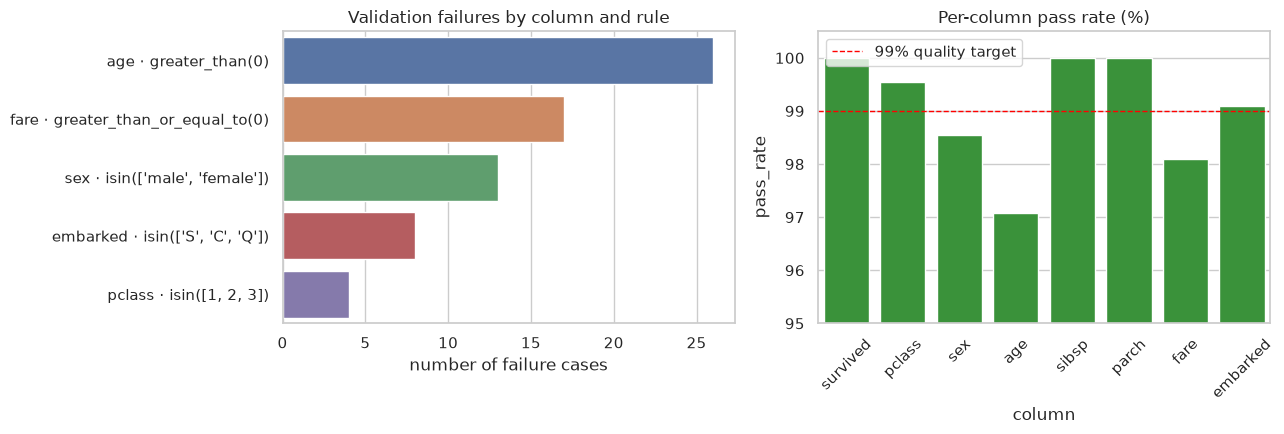

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

plot_df = validation_report.assign(rule=lambda d: d["column"] + " · " + d["check"].str.slice(0, 28))
sns.barplot(data=plot_df, y="rule", x="n_failures", hue="column", dodge=False, legend=False, ax=axes[0])
axes[0].set_title("Validation failures by column and rule")
axes[0].set_xlabel("number of failure cases")
axes[0].set_ylabel("")

# Pass rate per column across the batch
col_fail = fc.groupby("column")["index"].nunique().reindex(cols, fill_value=0)
pass_rate = (100 * (1 - col_fail / len(batch))).rename("pass_rate").reset_index()
sns.barplot(data=pass_rate, x="column", y="pass_rate", color="tab:green", ax=axes[1])
axes[1].set_ylim(95, 100.5)
axes[1].axhline(99, ls="--", c="red", lw=1, label="99% quality target")
axes[1].set_title("Per-column pass rate (%)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

In [31]:
# Structured error message: useful to log as JSON or send to a monitoring system.
try:
    report_schema.validate(batch, lazy=True)
except SchemaErrors as err:
    structured = err.message
    for error_type, items in structured.items():
        print(error_type)
        for kind, details in items.items():
            print(f"  {kind}: {len(details)} item(s) -> {details[0]}")

DATA
  DATAFRAME_CHECK: 5 item(s) -> {'schema': 'TitanicLoad', 'column': 'pclass', 'check': 'isin([1, 2, 3])', 'error': "Column 'pclass' failed element-wise validator number 0: isin([1, 2, 3]) failure cases: 4, 4, 4, 4"}


In [32]:
# Compare data quality across the clean original, the corrupted batch, and the learner demo data.
def quality_score(df: pd.DataFrame, schema) -> float:
    """Percentage of rows with zero validation failures."""
    ok, fc = safe_validate(df, schema)
    if ok:
        return 100.0
    bad = fc["index"].dropna().nunique()
    return round(100 * (1 - bad / len(df)), 2)


quality = pd.DataFrame(
    {
        "dataset": ["titanic (original)", "titanic (corrupted batch)", "learners (synthetic, clean)", "learners (dirty sample)"],
        "rows": [len(titanic), len(batch), len(learners), len(dirty)],
        "pct_valid_rows": [
            quality_score(titanic[cols], report_schema),
            quality_score(batch, report_schema),
            quality_score(learners, LearnerAssessment.to_schema()),
            quality_score(dirty, LearnerAssessment.to_schema()),
        ],
    }
)
quality

,dataset,rows,pct_valid_rows
0,titanic (original),891,100.00
1,titanic (corrupted batch),891,92.59
2,"learners (synthetic, clean)",300,100.00
3,learners (dirty sample),10,40.00


## Conclusão

### O que aprendi hoje
- **Validação como contrato:** `DataFrameSchema`, `Column` e `Check` tornam explícitas as suposições sobre tipos, faixas, categorias e relações entre colunas.
- **Eager vs lazy:** o modo `lazy=True` reúne todas as falhas e é a base para relatórios úteis.
- **Inferência de esquemas** (`infer_schema`, `to_script`) acelera o início, mas o esquema final deve refletir **conhecimento de domínio**, não os extremos da amostra.
- **Decorators** (`check_input`, `check_output`, `check_io`, `check_types`) validam cada etapa do pipeline na fronteira das funções.
- **Checks customizados e `Hypothesis`** permitem validar propriedades estatísticas (teste t, qui-quadrado) — úteis para monitorar *drift*.
- **`DataFrameModel`** oferece uma API declarativa, baseada em classes, que conversa com o que vi em `pydantic` (Dia 21).
- **Integração com scikit-learn:** um transformador de validação protege tanto o treino quanto a inferência.
- **Relatórios:** `failure_cases` → resumo por coluna/regra → visualização → padrão de quarentena.

### Conexão com linguística e educação
Planilhas de avaliação (níveis CEFR, notas, horas de estudo) e corpora anotados sofrem dos mesmos problemas: rótulos inexistentes, escalas misturadas, duplicatas. Um esquema versionado é a forma de garantir que análises de proficiência e modelos de NLP educacional partam de dados confiáveis.

### Limitações
- Os dados de aprendizes são **sintéticos** (semente fixa) e servem apenas para demonstrar a API.
- Os testes de hipótese aqui monitoram propriedades conhecidas; não são análises inferenciais completas.

### Próximos passos
- Comparar Pandera com **Great Expectations** e validação em **Polars**.
- Integrar esquemas aos testes com `pytest` (Dia 10) e a um CI.
- Usar Pandera na Fase 2 (EDA) como primeira etapa de cada análise.